In [7]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import tensorflow as tf
from tensorflow import keras
from keras import models,layers

In [2]:
path=r"D:\deep learning\mnist.npz"
data=np.load(path)
x_train=data["x_train"]
x_test=data["x_test"]
y_train=data["y_train"]
y_test=data["y_test"]

print(f"Shape of x_train : {x_train.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of x_test: {x_test.shape}")
print(f"Shape of y_test: {y_test.shape}")

Shape of x_train : (60000, 28, 28)
Shape of y_train: (60000,)
Shape of x_test: (10000, 28, 28)
Shape of y_test: (10000,)


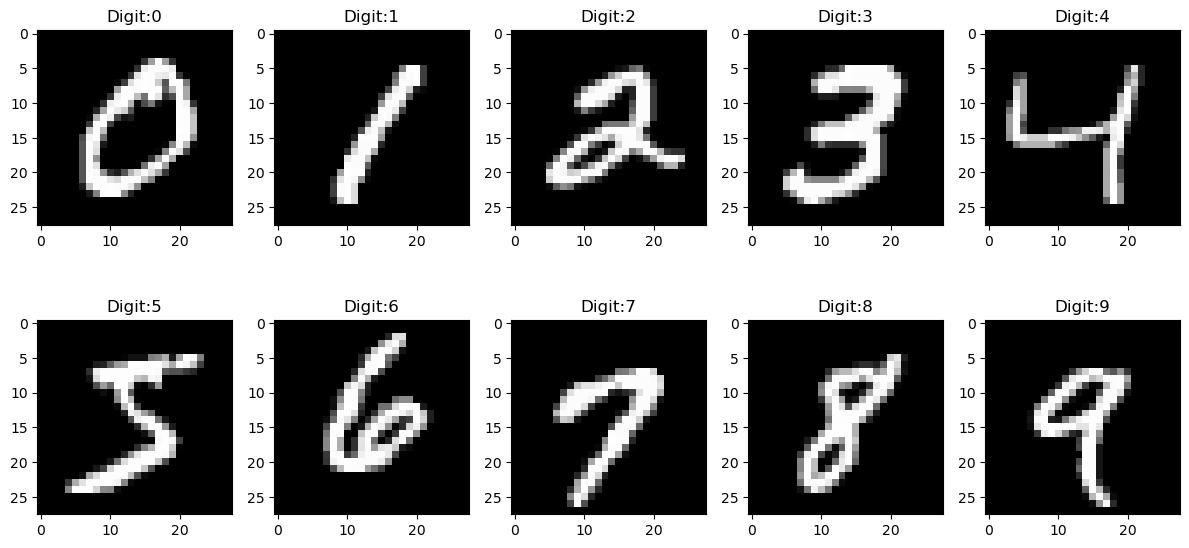

In [10]:
fig,axes=plt.subplots(2,5,figsize=(12,6))
axes=axes.flatten()
for i in range(10):
    idx=np.where(y_train==i)[0][0]
    axes[i].imshow(x_train[idx],cmap='gray')
    axes[i].set_title(f"Digit:{i}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

In [12]:
max_pixel_value=x_train.max()
x_train=x_train.astype("float32")/max_pixel_value
x_test=x_test.astype("float32")/max_pixel_value

In [14]:
model=models.Sequential([
    layers.Input(shape=(28,28)),
    layers.Flatten(), 
    layers.Dense(256,activation='relu'),
    layers.Dense(128,activation='tanh'), 
    layers.Dense(64,activation='relu'), 
    layers.Dense(10,activation='softmax')
                        ])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
history=model.fit(x_train,y_train,epochs=10,batch_size=32,validation_split=0.1)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.8453 - loss: 0.5914 - val_accuracy: 0.9282 - val_loss: 0.2436
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - accuracy: 0.9242 - loss: 0.2611 - val_accuracy: 0.9508 - val_loss: 0.1798
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9401 - loss: 0.2038 - val_accuracy: 0.9587 - val_loss: 0.1514
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9499 - loss: 0.1692 - val_accuracy: 0.9647 - val_loss: 0.1288
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - accuracy: 0.9576 - loss: 0.1440 - val_accuracy: 0.9670 - val_loss: 0.1146
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.9633 - loss: 0.1257 - val_accuracy: 0.9700 - val_loss: 0.1072
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9680 - loss: 0.1102 - val_accuracy: 0.9715 - val_loss: 0.1041
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9715 - loss: 0

In [16]:
test_loss,test_accuracy=model.evaluate(x_test,y_test)
print("test loss:",test_loss)
print("test acc:",test_accuracy*100,"%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9592 - loss: 0.1506
test loss: 0.15058507025241852
test acc: 95.92000246047974 %


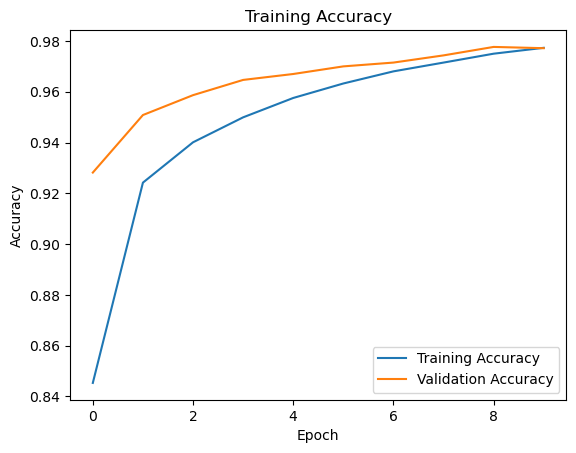

In [17]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

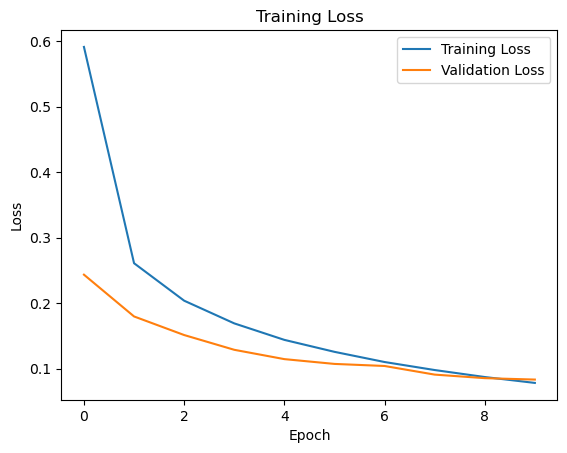

In [18]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()